# Contextual Alertness

## Project Statement

At the December 31, 2024 close a fictional long-short equity fund, Contextual Alertness, holds six memory, optical-networking and data-center names against six application-software names: 400% gross, 0% net, equal weights within each sleeve. The book is a stylized stand-in inspired by a real fund's publicly reported positioning. It is not that fund's holdings. Over the next eighteen months the book rises many-fold, then loses most of that gain in four sessions, July 24 to 29, 2026.

You are the risk manager. Take the book as given. Measure its risk, locate where the risk sat, say what a one-day VaR could and could not have told you, and build the version of the same strategy you would have been willing to run.


## Context

| Long, +1/3 of NAV each | Theme | Short, -1/3 of NAV each | Theme |
|---|---|---|---|
| `SNDK` | memory and storage | `ADBE` | application software |
| `MU` | memory | `CRM` | application software |
| `VRT` | data-center power and cooling | `ORCL` | enterprise software |
| `LITE` | optical networking | `NOW` | enterprise software |
| `COHR` | optical networking | `WDAY` | application software |
| `BE` | data-center power | `MDB` | database software |

The long sleeve is +200% of NAV and the short sleeve -200%, so gross exposure is 400% and net exposure is zero. The `SNDK` column is one strategy slot: it carries `WDC` returns through February 21, 2025 and `SNDK` returns from February 24, 2025, when Sandisk began regular-way trading; the switch is already in the supplied series.

The fund runs a mandate. At every close the book is reset to the target weights, so gross stays at 4x and net at zero: the **4x book**. Dividing every weight by four gives the **1x book**, the same positions at 100% gross.

Everything through July 31, 2026 is yours to study. The holdout, August 3 to October 26, 2026, exists for one purpose: Section 6 has you declare criteria, build controls on the design window, then run them, unchanged, on the holdout. Do not tune anything to it. If you study it earlier, the test in 6.3 stops measuring anything.


## Data

| File | Sheets | Frequency | Sample |
|---|---|---|---|
| `data/project_situational_awareness_20261026.xlsx` | `descriptions`, `total return indexes`, `total returns`, `baseline weights`, `data source`, `checks` | daily | 2020-12-31 to 2026-10-26 |

The `total returns` sheet holds the twelve names, `SPY`, `QQQ`, `SMH`, the eleven sector ETFs (`XLK XLI XLF XLC XLRE XLE XLY XLB XLV XLU XLP`) and `SHV`, as gross-dividend total returns. `descriptions` gives each ticker's name, theme and side; `baseline weights` gives the twelve target weights.


#### Notes

- Returns are daily, close to close, simple total returns. A weight set at the close of $t$ earns the return of $t+1$: $r^{\text{book}}_{t+1} = \boldsymbol{w}_t' \boldsymbol{r}_{t+1}$. Annualize with 252 trading days.
- The daily reset is a strategy-index convention: resetting to the target weights at every close makes 4x the book's exposure on every day, so Sections 3 to 5 measure the risk of a fixed-leverage book. Section 2 shows what the convention assumes away.
- Cash is `SHV`. Names and factors enter every regression in excess of `SHV`. The book's weights sum to zero, so its return $\boldsymbol{w}'\boldsymbol{r}$ is already an excess return and its Sharpe ratio uses it directly; the fund's NAV earns `SHV` on top of it.
- VaR and CVaR are positive loss magnitudes, one-day at the 5% level unless a question says otherwise. A forecast for day $t$ uses data through $t-1$. A breach is a day whose realized loss exceeds the VaR forecast made for it. EWMA uses $\lambda = 0.94$ and a zero mean; you choose how to initialize $\sigma^2$ and state it.
- The **design window** ends July 31, 2026. The **report window** is January 2, 2025 to July 31, 2026. The **holdout** runs from August 3, 2026 to October 26, 2026, the end of the file. Use the design window for all estimation and design. Open the holdout once, in 6.3, to evaluate the controls and criteria already specified. The final recommendation in 7.4 may use that verdict; do not re-tune the controls on the holdout.
- The **four-day loss** is the compounded loss of the daily-reset 4x book over July 24 to 29, 2026, $1 - \prod_{t=1}^{4}(1 + r_t)$, with $r_t$ the book's daily return.
- Ignore financing, stock-borrow fees, transaction costs, taxes and market impact.


## Data Preview


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

DATA = Path('../data') / 'project_situational_awareness_20261026.xlsx'
descriptions = pd.read_excel(DATA, sheet_name='descriptions').set_index('ticker')
returns = pd.read_excel(DATA, sheet_name='total returns', index_col='Date', parse_dates=True)
weights = pd.read_excel(DATA, sheet_name='baseline weights').set_index('ticker')['equal-sleeve weight']

LONGS = weights[weights > 0].index.tolist()
SHORTS = weights[weights < 0].index.tolist()
NAMES = weights.index.tolist()

DESIGN_END = pd.Timestamp('2026-07-31')
REPORT_START = pd.Timestamp('2025-01-02')
HOLDOUT_START = pd.Timestamp('2026-08-03')
REVERSAL_DAYS = pd.to_datetime(['2026-07-24', '2026-07-27', '2026-07-28', '2026-07-29'])

print(f'{returns.shape[1]} series, {returns.index[0].date()} to {returns.index[-1].date()}; design window ends {DESIGN_END.date()}')
print('longs:', LONGS)
print('shorts:', SHORTS)


27 series, 2021-01-04 to 2026-10-26; design window ends 2026-07-31
longs: ['SNDK', 'MU', 'VRT', 'LITE', 'COHR', 'BE']
shorts: ['ADBE', 'CRM', 'ORCL', 'NOW', 'WDAY', 'MDB']


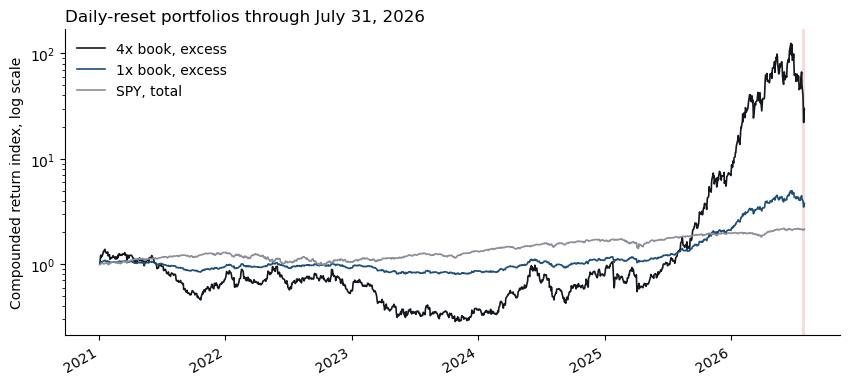

,SPY,SMH,XLK,SHV
Date,,,,
2026-07-20,-0.16%,+0.41%,+0.07%,+0.01%
2026-07-21,+0.83%,+4.52%,+2.89%,-0.01%
2026-07-22,-0.12%,+0.48%,-0.28%,+0.02%
2026-07-23,-1.23%,-1.15%,-1.01%,-0.01%
2026-07-24,+0.10%,-3.27%,-1.44%,+0.03%
2026-07-27,+0.02%,-2.25%,-0.90%,+0.01%
2026-07-28,+0.24%,-3.45%,-1.84%,+0.03%
2026-07-29,-1.54%,-4.79%,-2.64%,+0.03%
2026-07-30,+1.68%,+6.88%,+5.50%,+0.01%


In [3]:
design_returns = returns.loc[:DESIGN_END]
assert design_returns.index.max() <= DESIGN_END
book_4x = design_returns[weights.index] @ weights
book_1x = book_4x / 4
nav = pd.DataFrame({'4x book, excess': (1 + book_4x).cumprod(), '1x book, excess': (1 + book_1x).cumprod(), 'SPY, total': (1 + design_returns['SPY']).cumprod()})

fig, ax = plt.subplots(figsize=(10, 4.5))
nav.plot(ax=ax, color=['#14181e', '#1f4e79', '#8a8f98'], lw=1.2)
ax.axvspan(pd.Timestamp('2026-07-24'), DESIGN_END, color='#c1121f', alpha=0.10)
ax.set_yscale('log'); ax.set_ylabel('Compounded return index, log scale'); ax.set_xlabel('')
ax.set_title('Daily-reset portfolios through July 31, 2026', loc='left')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
plt.show()

reversal = returns[['SPY', 'SMH', 'XLK', 'SHV']].loc['2026-07-20':'2026-07-31']
reversal.index = reversal.index.strftime('%Y-%m-%d')
reversal.style.format('{:+.2%}', na_rep='-').set_caption('Factor returns around the reversal')


***


# 1. The Book as Given


## 1.1

Verify the long, short, gross and net exposures as multiples of NAV and as dollars on $100 million of NAV. Then, for the 4x book and the 1x book, report over 2021-01-04 to 2026-06-30 and over 2025-01-02 to 2026-06-30:

* annualized mean and volatility, Sharpe ratio, skewness, excess kurtosis
* worst day, empirical 5% VaR and CVaR
* maximum drawdown with its peak and trough dates, and cumulative return

Group the statistics by how they respond to leverage. Explain the scaling and compounding within each group.


#### Drawdown Formulas

- Compounded NAV: $V_t = \prod_{s=1}^{t} (1 + r_s)$
- Running peak: $P_t = \max_{s \le t} V_s$
- Drawdown: $DD_t = V_t / P_t - 1 \le 0$
- Maximum drawdown: $\text{MDD} = \min_t DD_t$, reached on the trough date $t^* = \arg\min_t DD_t$; the peak date is $\arg\max_{s \le t^*} V_s$
- Cumulative return: $V_T - 1$

In [4]:
def stats_table(r, ann=252):
    mu = r.mean() * ann
    vol = r.std() * np.sqrt(ann)
    sharpe = mu / vol
    skew = stats.skew(r)
    kurt = stats.kurtosis(r)
    worst = r.min()
    q = r.quantile(0.05)
    var5 = -q
    cvar5 = -r[r <= q].mean()
    nav_ = (1 + r).cumprod() 
    peak = nav_.cummax()
    dd = nav_ / peak - 1
    trough_date = dd.idxmin()
    peak_date = nav_.loc[:trough_date].idxmax()
    maxdd = dd.min()
    cum_ret = nav_.iloc[-1] - 1
    return pd.Series({
        'ann mean': mu, 'ann vol': vol, 'Sharpe': sharpe, 'skew': skew, 'excess kurt': kurt,
        'worst day': worst, 'VaR 5%': var5, 'CVaR 5%': cvar5,
        'max drawdown': maxdd, 'peak date': peak_date.date(), 'trough date': trough_date.date(),
        'cum return': cum_ret,
    })

NAV0 = 100e6
exposure = pd.DataFrame({
    '4x book': {'long (x NAV)': weights[LONGS].sum(), 'short (x NAV)': weights[SHORTS].sum(),
                'gross (x NAV)': weights.abs().sum(), 'net (x NAV)': weights.sum()},
    '1x book': {'long (x NAV)': weights[LONGS].sum()/4, 'short (x NAV)': weights[SHORTS].sum()/4,
                'gross (x NAV)': weights.abs().sum()/4, 'net (x NAV)': weights.sum()/4},
})
exposure_dollars = exposure * NAV0
print('Exposure as multiples of NAV:'); display(exposure.round(2))
print('Exposure in dollars, $100mm NAV:'); display(exposure_dollars.style.format('{:,.0f}'))

windows_1_1 = {
    '2021-01-04 to 2026-06-30': ('2021-01-04', '2026-06-30'),
    '2025-01-02 to 2026-06-30': ('2025-01-02', '2026-06-30'),
}
results_1_1 = {}
for label, (start, end) in windows_1_1.items():
    r4 = returns.loc[start:end, NAMES] @ weights 
    r1 = r4 / 4 
    results_1_1[(label, '4x')] = stats_table(r4)
    results_1_1[(label, '1x')] = stats_table(r1)

table_1_1 = pd.DataFrame(results_1_1).T
pct = ['ann mean', 'ann vol', 'worst day', 'VaR 5%', 'CVaR 5%', 'max drawdown', 'cum return']
display(table_1_1.style.format('{:.2%}', subset=pct)
                       .format('{:.2f}', subset=['Sharpe', 'skew', 'excess kurt']))

Exposure as multiples of NAV:


,4x book,1x book
long (x NAV),2.0,0.5
short (x NAV),-2.0,-0.5
gross (x NAV),4.0,1.0
net (x NAV),0.0,0.0


Exposure in dollars, $100mm NAV:


,4x book,1x book
long (x NAV),"200,000,000","50,000,000"
short (x NAV),"-200,000,000","-50,000,000"
gross (x NAV),"400,000,000","100,000,000"
net (x NAV),0,0


**Answer 1.1**

**Exposures:** 4x book: long +2.0x ($200mm), short −2.0x (−$200mm), gross 4.0x ($400mm), net 0. 1x book: ±0.5x ($50mm each side), gross 1.0x ($100mm), net 0.

**Leverage effect:**
| Group | Statistics | 4x vs 1x |
|---|---|---|
| Scale by 4 | mean, volatility, worst day, VaR, CVaR | Each day the 4x return is exactly 4 × the 1x return, so levels, quantiles and tail means scale by 4 (full window: vol 22.5% to 89.9%, VaR 1.8% to 7.3%, CVaR 3.1% to 12.4%). |
| Unchanged | Sharpe, skewness, excess kurtosis | For ratios and standardized moments the 4 cancels (Sharpe 1.39 and 3.11 in both books). |
| Compound (non-linear) | max drawdown, cumulative return | These statistics are path dependent. Losses compound, so the full-window drawdown goes from 26% to 79% (not to 105%). Gains compound too, as seen by the fact that 2025-26 cumulative return is 340% at 1x and 12,690% at 4x.|

**Worst day:**
The worst day (−36.0% at 4x) is January 27, 2025, so it shows up in both windows.

## 1.2

Report the compounded calendar-year return of the 4x book for 2021 through 2026 (to July 31), with the contribution of each sleeve, defined as the sum of the sleeve's daily weighted returns. The sleeve contributions add to the sum of the book's daily returns rather than to its compounded year; report both. In which years did the short sleeve add to the return, and in which did it subtract?


In [5]:
long_4x = design_returns[LONGS] @ weights[LONGS]
short_4x = design_returns[SHORTS] @ weights[SHORTS]
year = book_4x.index.year

table_1_2 = pd.DataFrame({
    'compounded return': book_4x.groupby(year).apply(lambda r: (1 + r).prod() - 1),
    'sum of daily returns': book_4x.groupby(year).sum(),
    'long sleeve': long_4x.groupby(year).sum(),
    'short sleeve': short_4x.groupby(year).sum(),
})
table_1_2.index.name = 'year'
table_1_2.style.format('{:+.1%}')

,compounded return,sum of daily returns,long sleeve,short sleeve
year,,,,
2021,-28.9%,-19.4%,+36.6%,-55.9%
2022,-20.7%,-3.8%,-79.1%,+75.3%
2023,-34.8%,-25.1%,+100.5%,-125.6%
2024,+110.6%,+101.5%,+123.5%,-22.0%
2025,+795.5%,+274.6%,+288.8%,-14.2%
2026,+325.8%,+267.5%,+223.7%,+43.9%


In [6]:
jul_23 = (1 + book_4x.loc['2026-01-01':'2026-07-23']).prod() - 1 
jul_31 = (1 + book_4x.loc['2026']).prod() - 1 

gain_erased = (jul_23 - jul_31) / jul_23

print(f"YTD to Jul 23: {jul_23:.0%} | YTD to Jul 31: {jul_31:.0%} | Gain erased: {gain_erased:.0%}")

YTD to Jul 23: 863% | YTD to Jul 31: 326% | Gain erased: 62%


**Answer 1.2.**

The short sleeve was negative in 2021, 2023, 2024, and 2025, subtracting from total returns. It contributed to negative returns in 2021 and 2023, with a significant rally in 2023, as its losses exceeded the long sleeve's gains. The only years in which the short sleeve added to returns were 2022, where it contributed a sum of daily returns of 75%, and 2026 (+44%). 2022 is the only year it actually hedged, as in 2026 both sleeves gained.

Comparing the compounded book return with the sum of daily book returns we see a significant difference between 2025 and 2026. Noting that 2026 only contains 7 months of returns, we see that the sum of daily book returns in both time periods is almost equal (274.6% in 2025 vs 267.5% in the first 7 months of 2026), whereas the compounded book return in 2025 is almost 2.5 times as large as that of 2026 (795.5% vs 325.8%). This reveals the fact that the path of returns matters: indeed, the July loss was such that it wiped out about 62% of the year to date gains (the book was up 863% through July 23 and only 326% by July 31), which is something the sum of daily returns does not show.

## 1.3

Over both windows in 1.1, report

* the average pairwise correlation among the long names, among the short names, and between a long and a short name
* the correlation between the long basket's return and the short basket's return

What, if anything, does the short sleeve hedge?


In [7]:
def avg_corr(corr, rows, cols):
    sub_corr = corr.loc[rows, cols].values
    if rows == cols: 
        return sub_corr[np.triu_indices_from(sub_corr, k=1)].mean()
    return sub_corr.mean()

long_basket = returns[LONGS].mean(axis=1)
short_basket = returns[SHORTS].mean(axis=1)

table_1_3 = {}
for label, (start, end) in windows_1_1.items():
    corr = returns.loc[start:end, NAMES].corr()
    table_1_3[label] = {
        'long vs long': avg_corr(corr, LONGS, LONGS),
        'short vs short': avg_corr(corr, SHORTS, SHORTS),
        'long vs short': avg_corr(corr, LONGS, SHORTS),
        'long basket vs short basket': long_basket.loc[start:end].corr(short_basket.loc[start:end]),
    }
pd.DataFrame(table_1_3).style.format('{:.2f}')

,2021-01-04 to 2026-06-30,2025-01-02 to 2026-06-30
long vs long,0.48,0.55
short vs short,0.50,0.50
long vs short,0.24,0.11
long basket vs short basket,0.43,0.23


**Answer 1.3**

Names inside a sleeve move together (about 0.5), whereas across sleeves the correlation is low (0.24 over the full window and only 0.11 in 2025-26). The basket correlation also falls from 0.43 to 0.23 from the full to the recent window. The later means that a short position with p of c. 0.2 removes only about 5% (ρ²) of the long basket's variance. This means that the short sleeve hedges a small part of the general equity market and none of the memory/AI-infrastructure theme. Therefore it acts as a second bet (short software), not as a hedge.

## 1.4

For each window in 1.1, report the standard error of the 4x book's annualized mean and of its Sharpe ratio, and the Sharpe ratio's 95% band. You are reviewing the book on June 30, 2026 with the statistics from 1.1 to 1.4 in hand. Which window would you base a risk assessment on, and what is a Sharpe ratio estimated on eighteen months of daily data evidence of? Answer in a short paragraph that uses the standard errors.

#### Estimation Error

Under independence, the standard error of an annualized mean estimated from $N$ years of daily data is $\sigma_{\text{ann}}/\sqrt{N}$. With $q = 252$ periods a year, the annualized Sharpe ratio has standard error $\sqrt{(1 + \text{SR}^2/2q)/N}$.


In [8]:
table_1_4 = {}
for label, (start, end) in windows_1_1.items():
    r = book_4x.loc[start:end]
    years = len(r) / 252
    mean, vol = r.mean() * 252, r.std() * np.sqrt(252)
    sharpe = mean / vol
    se_sharpe = np.sqrt((1 + sharpe**2 / (2 * 252)) / years)
    table_1_4[label] = {
        'years': years, 'ann mean': mean, 'SE of mean': vol / np.sqrt(years),
        'Sharpe': sharpe, 'SE of Sharpe': se_sharpe,
        'Sharpe 95% low': sharpe - 1.96 * se_sharpe, 'Sharpe 95% high': sharpe + 1.96 * se_sharpe,
    }
pd.DataFrame(table_1_4).round(2)

,2021-01-04 to 2026-06-30,2025-01-02 to 2026-06-30
years,5.47,1.48
ann mean,1.25,4.25
SE of mean,0.38,1.12
Sharpe,1.39,3.11
SE of Sharpe,0.43,0.83
Sharpe 95% low,0.55,1.48
Sharpe 95% high,2.23,4.74


**Answer 1.4.**

We would base the risk assessment on the full window, as the standard errors for the mean and the Sharpe are around a third and half as large as the ones for the recent window (0.38 vs 1.12 for the mean and 0.43 vs 0.83 for the Sharpe, respectively). Furthermore, it includes 2021 to 2023, a regime in which the strategy lost money.

The Sharpe ratio estimated on the 18 months of data, 3.11, is evidence that the trade was working during that regime, but not necessarily an indication of the strategy's expected Sharpe. While it is high, its SE is also high (95% band of 1.48 to 4.74, vs 0.55 to 2.23 for the full window), and even higher if we consider the possibility that returns are not iid.

# 2. The Reset


## 2.1

Start on 2025-01-02 with $100 million of NAV and positions set to the 4x target weights at the prior close. Hold cash as collateral without interest. Compare three rules:

- Reset to target weights at every close.
- Reset at every month-end close.
- Hold the initial shares without rebalancing.

Gross exposure is measured at each close for the following day. Report:

- NAV and gross leverage through July 31, 2026, as plots.
- For each rule: gross exposure set on June 22 and July 23, NAV relative to its initial value on June 22, the July 24 to 29 return, and whether and when NAV reaches zero.
- For fixed shares initialized on 2021-01-04: maximum gross exposure and minimum NAV, with their dates.
- For fixed shares initialized at the July 23, 2026 close to the 4x target on $100 million: NAV, long exposure, short exposure, and gross leverage at each of the four closes through July 29. Compare NAV with the daily-reset portfolio over the same four days.

Could a fund have maintained each path? Use the gross exposures and NAV paths to explain what daily resetting assumes about the fund as a going concern, which convention a real fund lives under, and why the same positions lose different fractions of NAV over the reversal.


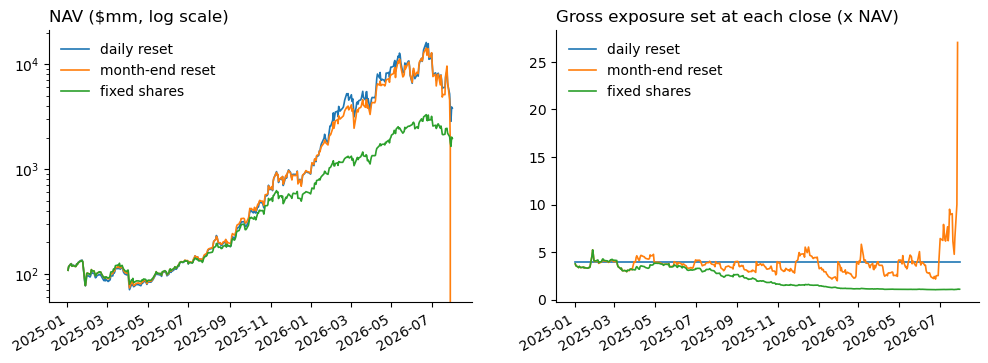

,gross set Jun 22,gross set Jul 23,"NAV / initial, Jun 22",Jul 24-29 return,NAV reaches zero
daily reset,4.0,4.0,161.326897,-0.669055,no
month-end reset,2.223807,4.77108,142.655171,-1.102263,2026-07-29
fixed shares,1.054644,1.065379,33.03944,-0.326702,no


In [9]:
def simulate(rets, rebalance_dates, nav0=100e6):
    """Dollar book: positions drift with returns, cash earns nothing, reset to target on rebalance dates."""
    position = weights * nav0
    nav = nav0
    path = []
    for date, r in rets.iterrows():
        nav += (position * r).sum()
        position = position * (1 + r)
        if nav <= 0:
            path.append((date, nav, np.nan, np.nan, np.nan))
            break
        if date in rebalance_dates:
            position = weights * nav
        long_exp, short_exp = position[LONGS].sum(), position[SHORTS].sum()
        #leverage: long leverage, short leverage, gross leverage=(long-short)/NAV
        path.append((date, nav, long_exp / nav, short_exp / nav, (long_exp - short_exp) / nav))
    return pd.DataFrame(path, columns=['date', 'nav', 'long', 'short', 'gross']).set_index('date')

rets_2025 = design_returns.loc[REPORT_START:, NAMES]
month_ends = rets_2025.index.to_series().groupby(rets_2025.index.to_period('M')).max()
rules = {
    'daily reset': simulate(rets_2025, set(rets_2025.index)),
    'month-end reset': simulate(rets_2025, set(month_ends)),
    'fixed shares': simulate(rets_2025, set()),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, path in rules.items():
    (path['nav'] / 1e6).plot(ax=axes[0], label=name, lw=1.2)
    path['gross'].plot(ax=axes[1], label=name, lw=1.2)
axes[0].set_yscale('log'); axes[0].set_title('NAV ($mm, log scale)', loc='left')
axes[1].set_title('Gross exposure set at each close (x NAV)', loc='left')
for ax in axes:
    ax.legend(frameon=False); ax.set_xlabel(''); ax.spines[['top', 'right']].set_visible(False)
plt.show()

summary_2_1 = {}
for name, path in rules.items():
    hit_zero = path.index[path['nav'] <= 0]
    summary_2_1[name] = {
        'gross set Jun 22': path.loc['2026-06-22', 'gross'],
        'gross set Jul 23': path.loc['2026-07-23', 'gross'],
        'NAV / initial, Jun 22': path.loc['2026-06-22', 'nav'] / 100e6,
        'Jul 24-29 return': path.loc['2026-07-29', 'nav'] / path.loc['2026-07-23', 'nav'] - 1,
        'NAV reaches zero': hit_zero[0].date() if len(hit_zero) else 'no',
    }
pd.DataFrame(summary_2_1).T

In [10]:
#fixed shars from 2021-01-04, no rebalancing
fixed_2021 = simulate(design_returns.loc['2021-01-04':, NAMES], set())
pd.Series({
    'max gross (x NAV)': fixed_2021['gross'].max(), 'date of max gross': fixed_2021['gross'].idxmax().date(),
    'min NAV ($mm)': fixed_2021['nav'].min() / 1e6, 'date of min NAV': fixed_2021['nav'].idxmin().date(),
    'NAV on Jul 31, 2026 ($mm)': fixed_2021['nav'].iloc[-1] / 1e6,
}).to_frame('fixed shares from 2021-01-04')

,fixed shares from 2021-01-04
max gross (x NAV),22.12416
date of max gross,2021-10-22
min NAV ($mm),18.485846
date of min NAV,2023-07-19
"NAV on Jul 31, 2026 ($mm)",2306.066676


In [11]:
reversal_rets = design_returns.loc['2026-07-24':'2026-07-29', NAMES]
fixed_jul = simulate(reversal_rets, set()) #fixed shares from July 24, 2026
table_2_1c = pd.DataFrame({
    'fixed NAV ($mm)': fixed_jul['nav'] / 1e6,
    'long (x NAV)': fixed_jul['long'],
    'short (x NAV)': fixed_jul['short'],
    'gross (x NAV)': fixed_jul['gross'],
    'daily-reset NAV ($mm)': 100 * (1 + book_4x.loc[reversal_rets.index]).cumprod(),
})
table_2_1c.index = table_2_1c.index.date
table_2_1c.round(2)

,fixed NAV ($mm),long (x NAV),short (x NAV),gross (x NAV),daily-reset NAV ($mm)
2026-07-24,75.11,2.42,-2.75,5.16,75.11
2026-07-27,55.74,3.13,-3.92,7.06,60.40
2026-07-28,30.06,5.24,-7.56,12.80,43.85
2026-07-29,7.55,18.96,-31.20,50.17,33.09


In [12]:
rev = returns.loc['2026-07-24':'2026-07-29']

long_leg  = rev[LONGS] @ weights[LONGS]
short_leg = rev[SHORTS] @ weights[SHORTS]

pd.DataFrame({'long leg': long_leg, 'short leg': short_leg,
              'book': long_leg + short_leg}).style.format('{:+.1%}')

,long leg,short leg,book
Date,,,
2026-07-24 00:00:00,-18.5%,-6.4%,-24.9%
2026-07-27 00:00:00,-7.7%,-11.9%,-19.6%
2026-07-28 00:00:00,-19.8%,-7.6%,-27.4%
2026-07-29 00:00:00,-17.6%,-7.0%,-24.5%


| Rule | Gross Jun 22 / Jul 23 | NAV / initial Jun 22 | Jul 24-29 | NAV to zero |
|---|---|---|---|---|
| Daily reset | 4.0x / 4.0x | 161x | −66.9% | no |
| Month-end reset | 2.2x / 4.8x | 143x | −110% | July 29, 2026 |
| Fixed shares (2025) | 1.05x / 1.07x | 33x | −32.7% | no |

Fixed shares from 2021 reach 22.1x gross (2021-10-22) and NAV bottoms at $18.5mm (2023-07-19); fixed shares from July 23 fall to $7.6mm at 50x gross in four days, while the daily-reset book ends at $33.1mm.

**Answer 2.1**

**Could a fund have maintained each path?**

In terms of sustainability of the strategy, a fund could have mantained both the daily reset and the fixed shares portfolios, as neither would "blow up" (NAV going to zero) as the monthly reset portfolio did. However, the fixed shares portfolio would not comply with the fund's mandate of being long 2x hardware and short 2x software (as seen by the fact that its gross exposure trends down and essentially becomes an unlevered bet on hardware).

**What does daily resetting assume about the fund as a going concern?**
Daily resetting assumes a fund can always trade its whole book at the market close for free, in any size, and that just keeps going at 4x no matter what happened the day before. Daily reset trades about 25% of NAV at every close on average, and 103-134% of NAV at each close during the reversal, selling the longs into the drop and buying back the shorts into their rally. 

**Which convention does a real fund live under?**
A real fund lives under fixed shares between trades: its leverage is whatever its positions are worth relative to its NAV that day, and losses push leverage up until someone (the risk manager or the prime broker) forces it down.

**Why do the same positions lose different fractions of NAV over the reversal?**
The difference is mainly due to gross exposure. On a given day, a book with equal long and short sides returns (gross/2) × (long basket − short basket return). Going into July 24 the fixed, daily rebalanced and monthly rebalanced portfolios had gross of 1.07x, 4x and 4.8x, respectively, and lost 33%, 67% and 110% over the four days. The gap widens because  the monthly portfolioàs gross exposure continues to rise NAV falls (reaching 27x by July 28).

# 3. One-Day VaR Through the Reversal


## 3.1

Compute the EWMA volatility forecast of the 4x book from the first day your initialization allows to July 31, 2026, and, for every day in the design window, three one-day 5% VaR forecasts and the CVaR of each: historical simulation, Normal EWMA and filtered historical simulation.

* Plot the EWMA forecast annualized; report the forecast made for July 24, 2026 and the fraction of forecasts for days through June 30, 2026 that were lower.
* Report the three VaR and CVaR forecasts made at the July 23, 2026 close.

#### VaR Conventions

Historical simulation: minus the 5% quantile of the trailing 252 daily returns; the CVaR is minus the mean of the returns at or below that quantile. Normal EWMA: $\text{VaR}_t = -z_{0.05}\,\sigma_t$ and $\text{CVaR}_t = \sigma_t\,\phi(z_{0.05})/0.05$, with $\sigma_t$ the EWMA forecast. Filtered historical simulation: standardize each past return by the EWMA forecast that applied to it, $z_s = r_s/\sigma_s$; take the 5% quantile and the tail mean of the standardized returns over the trailing 252 days, the same window as the historical simulation; multiply both by the current forecast $\sigma_t$.


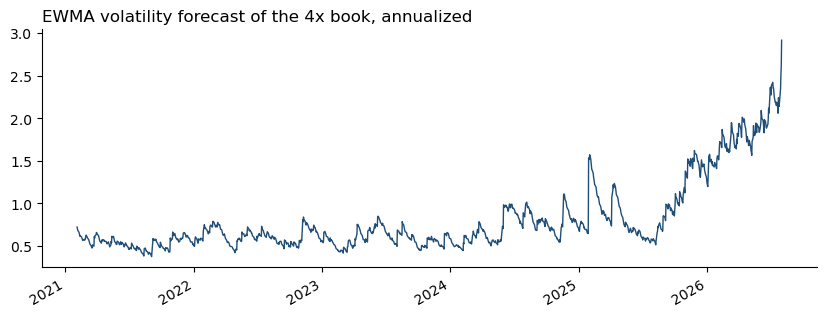

In [ ]:
LAMBDA, ALPHA, WINDOW, INIT_DAYS = 0.94, 0.05, 252, 21

def ewma_sigma(r, lam=LAMBDA, init_days=INIT_DAYS):
    """sigma[t] is the forecast for day t using returns through t-1; seeded with the mean square of the first init_days."""
    x = r.values
    var = np.full(len(x), np.nan)
    #ewma
    var[init_days] = np.mean(x[:init_days] ** 2)
    for t in range(init_days + 1, len(x)):
        var[t] = lam * var[t - 1] + (1 - lam) * x[t - 1] ** 2
    return pd.Series(np.sqrt(var), index=r.index)

def tail_stats(x, alpha=ALPHA): #var, cvar
    q = np.quantile(x, alpha)
    return -q, -x[x <= q].mean()

def var_forecasts(r, window=WINDOW, alpha=ALPHA):
    sigma = ewma_sigma(r)
    z = (r / sigma).values #standardized returns for filtered historical simulation
    x = r.values
    out = pd.DataFrame(np.nan, index=r.index, columns=['sigma', 'HS VaR', 'HS CVaR', 'EWMA VaR', 'EWMA CVaR', 'FHS VaR', 'FHS CVaR'])
    out['sigma'] = sigma
    z_alpha = stats.norm.ppf(alpha) #quantile of standard normal for EWMA VaR/CVaR
    out['EWMA VaR'] = -z_alpha * sigma
    out['EWMA CVaR'] = sigma * stats.norm.pdf(z_alpha) / alpha
    for t in range(window, len(x)):
        out.iloc[t, 1:3] = tail_stats(x[t - window:t], alpha)
        past_z = z[t - window:t]
        if not np.isnan(past_z).any():
            z_var, z_cvar = tail_stats(past_z, alpha)
            out.iloc[t, 5:7] = z_var * sigma.iloc[t], z_cvar * sigma.iloc[t]
    return out

forecasts = var_forecasts(book_4x)
ewma_ann = forecasts['sigma'] * np.sqrt(252)

fig, ax = plt.subplots(figsize=(10, 3.5))
ewma_ann.plot(ax=ax, color='#1f4e79', lw=1)
ax.set_title('EWMA volatility forecast of the 4x book, annualized', loc='left'); ax.set_xlabel('')
ax.spines[['top', 'right']].set_visible(False)
plt.show()



In [36]:
jul24_vol = ewma_ann.loc['2026-07-24']
print(f"First forecast: {ewma_ann.first_valid_index().date()}")
print(f"EWMA forecast for 2026-07-24: {jul24_vol:.1%} annualized ({forecasts.loc['2026-07-24', 'sigma']:.2%} daily)")
print(f"Share of forecasts through 2026-06-30 below it: {(ewma_ann.loc[:'2026-06-30'].dropna() < jul24_vol).mean():.1%}")
jul24 = forecasts.loc['2026-07-24']

First forecast: 2021-02-03
EWMA forecast for 2026-07-24: 213.9% annualized (13.48% daily)
Share of forecasts through 2026-06-30 below it: 99.9%


In [37]:
pd.DataFrame({'VaR':  [jul24['HS VaR'],  jul24['EWMA VaR'],  jul24['FHS VaR']],
              'CVaR': [jul24['HS CVaR'], jul24['EWMA CVaR'], jul24['FHS CVaR']]},
             index=['HS', 'EWMA', 'FHS']).style.format('{:.1%}')

,VaR,CVaR
HS,16.6%,20.9%
EWMA,22.2%,27.8%
FHS,21.3%,27.3%


**Answer 3.1**

**Initialization:** We choose the starting σ² as sample variance of the first 21 trading days, so the first forecast is for 2021-02-03. With λ = 0.94, its weight falls below 2% after three months, so the estimates after 2021 do not depend on it.

**Forecast:** 
- The EWMA forecast for July 24, 2026 is 214% annualized (13.5% daily), higher than 99.9% of all forecasts through June 30. The model was already at a record level before the reversal.
- At the July 23 close (table above), EWMA and FHS give VaR of 22.2% and 21.3% and CVaR of about 27%; HS gives 16.6% / 20.9%.
- HS is lowest because its 252-day window still holds the calmer days of 2025; EWMA and FHS react to the current volatility.

## 3.2

Backtest the three methods over 2025-01-02 to 2026-07-23 and over 2021-01-04 to 2024-12-31. For each method and window report

* the number of forecasts, the number of breaches and the hit ratio
* the longest run of consecutive breaches
* the mean realized loss on breach days beside the mean CVaR forecast on those days

A method whose window has not yet filled starts later; report its count and say so. Which methods are calibrated in each window, and where the hit ratio is near 5%, does the breach-day loss match the CVaR forecast?


In [14]:
def longest_run(flags): #length of longest consecutive day loss > var
    run = best = 0
    for flag in flags:
        run = run + 1 if flag else 0 #if flag is true, run +1
        best = max(best, run) #max length of run so far
    return best

def backtest(r, fc, start, end):
    table = {}
    for method in ['HS', 'EWMA', 'FHS']:
        var, cvar = fc.loc[start:end, f'{method} VaR'].dropna(), fc.loc[start:end, f'{method} CVaR']
        loss = -r.loc[var.index]
        breach = loss > var
        table[method] = {
            'first forecast': var.index[0].date(), 'forecasts': len(var), 'breaches': breach.sum(),
            'hit ratio': breach.mean(), 'longest run': longest_run(breach),
            'mean loss on breach': loss[breach].mean(), 'mean CVaR on breach': cvar[breach.index[breach]].mean(),
        }
    return pd.DataFrame(table).T

for label, (start, end) in {'2025-01-02 to 2026-07-23': ('2025-01-02', '2026-07-23'),
                            '2021-01-04 to 2024-12-31': ('2021-01-04', '2024-12-31')}.items():
    print(label)
    display(backtest(book_4x, forecasts, start, end).style.format(
        {'hit ratio': '{:.1%}', 'mean loss on breach': '{:.2%}', 'mean CVaR on breach': '{:.2%}'}))

2025-01-02 to 2026-07-23


,first forecast,forecasts,breaches,hit ratio,longest run,mean loss on breach,mean CVaR on breach
HS,2025-01-02,389,38,9.8%,2,15.40%,14.43%
EWMA,2025-01-02,389,15,3.9%,2,19.99%,17.80%
FHS,2025-01-02,389,23,5.9%,2,17.51%,18.53%


2021-01-04 to 2024-12-31


,first forecast,forecasts,breaches,hit ratio,longest run,mean loss on breach,mean CVaR on breach
HS,2022-01-03,753,44,5.8%,2,8.30%,7.96%
EWMA,2021-02-03,984,43,4.4%,2,8.32%,7.60%
FHS,2022-02-02,732,36,4.9%,2,8.31%,8.48%


**Answer 3.2**
- 2021-24: all three methods are calibrated. HS and FHS start later (2022-01-03 and 2022-02-02) because their 252-day windows must fill first.
- 2025-26: HS fails at 9.8%, because its 252-day window lags rising volatility; EWMA and FHS pass in general, although EWMA is more conservative whereas FHS is less conservative.
- CVaR: FHS matches the breach-day loss in both windows; EWMA understates it (20.0% vs 17.8%) because the Normal tail is too thin.
- FHS is the most accurate method in both windows, on both hit ratio and tail size.

## 3.3

For each of the four reversal days, July 24, 27, 28 and 29, report the realized loss of the 4x book as a multiple of the VaR each method had forecast for that day, and the four-day loss as a multiple of $\sqrt{4}$ times each method's July 23 forecast.

Over 2025-01-02 to 2026-07-31, compare overlapping 4-day returns of the 4x book with $\sqrt{4}$ times the Normal EWMA one-day VaR in force at the start of each window. Report:

- The hit ratio.
- The largest ratio of realized loss to scaled VaR, with its date.

For each method, count the reversal-day breaches. Does the four-day loss challenge $\sqrt{h}$ scaling? Say which of its assumptions (independent daily returns, constant volatility, a zero mean) could account for the gap between the scaled forecast and the realized loss, and what one four-day realization can and cannot establish about them. Is the largest one-day ratio on a reversal day?


In [ ]:
methods = ['HS', 'EWMA', 'FHS']
reversal_loss = -book_4x.loc[REVERSAL_DAYS]
four_day_loss = 1 - (1 + book_4x.loc[REVERSAL_DAYS]).prod() #formula
table_3_3 = pd.DataFrame({m: reversal_loss / forecasts.loc[REVERSAL_DAYS, f'{m} VaR'] for m in methods})
table_3_3.index = table_3_3.index.date
table_3_3.loc['4-day loss / (2 x Jul 23 VaR)'] = [four_day_loss / (2 * forecasts.loc['2026-07-24', f'{m} VaR']) for m in methods]
table_3_3.loc['reversal-day breaches'] = (table_3_3.iloc[:4] > 1).sum()
print(f'realized losses: {", ".join(f"{x:.1%}" for x in reversal_loss)}; four-day loss {four_day_loss:.1%}')
display(table_3_3.round(2))

r_report = book_4x.loc[REPORT_START:]
four_day_ret = (1 + r_report).rolling(4).apply(np.prod, raw=True).shift(-3) - 1 #compounded return over 4-day windows
scaled_var = 2 * forecasts.loc[REPORT_START:, 'EWMA VaR']
ratio_4d = (-four_day_ret / scaled_var).dropna() #four day ret/(2 x EWMA VaR) > 1, hit
print(f'overlapping 4-day windows: {len(ratio_4d)}, hit ratio vs sqrt(4) EWMA VaR: {(ratio_4d > 1).mean():.1%}')
print(f'largest 4-day ratio: {ratio_4d.max():.2f}, window starting {ratio_4d.idxmax().date()}')

one_day_ratio = pd.DataFrame({m: -r_report / forecasts.loc[REPORT_START:, f'{m} VaR'] for m in methods})
pd.DataFrame({'largest one-day ratio': one_day_ratio.max(), 'date': one_day_ratio.idxmax().dt.date}).T

realized losses: 24.9%, 19.6%, 27.4%, 24.5%; four-day loss 66.9%


,HS,EWMA,FHS
2026-07-24,1.50,1.12,1.17
2026-07-27,1.12,0.83,0.84
2026-07-28,1.53,1.13,1.15
2026-07-29,1.34,0.94,0.92
4-day loss / (2 x Jul 23 VaR),2.02,1.51,1.57
reversal-day breaches,4.00,2.00,2.00


overlapping 4-day windows: 392, hit ratio vs sqrt(4) EWMA VaR: 3.3%
largest 4-day ratio: 3.05, window starting 2025-01-23


,HS,EWMA,FHS
largest one-day ratio,5.225258,5.366342,6.65053
date,2025-01-27,2025-01-27,2025-01-27


**Answer 3.3**

Each reversal day was only about 0.8 to 1.5 times its VaR. HS breached on all four days; EWMA and FHS breached on two each (July 24 and 28). The four-day loss of 66.9% is 1.5 to 2.0 times $\sqrt{4}$ × VaR. On a one-day basis the models did not fail badly. What failed was four large losses in a row, all in the same direction.

Over the report window, 4-day losses beat $\sqrt{4}$ × EWMA VaR in only 3.3% of 392 overlapping windows, so $\sqrt{h}$ scaling is not too low on average. The largest ratio, 3.05, is the window starting 2025-01-23, not the reversal. The largest one-day ratio (5.2 to 6.7) is also January 27, 2025, not a reversal day.

Each assumption could explain the gap:
- **Independence:** four same-sign losses look like an unwind with positive autocorrelation, which makes 4-day variance larger than 4 × daily variance.
- **Constant volatility:** volatility was already at a record and kept rising during the four days.
- **Zero mean:** a negative drift in a crowded exit adds h × μ, not √h × μ.

One four-day realization cannot tell these apart or estimate any of them. It is consistent with a roughly 1-in-150 Normal tail draw (3.4). It shows the scaling can be badly wrong in a single event, not that it is biased.

## 3.4

Using the July 23 EWMA volatility scaled by $\sqrt{4}$ and a zero mean, compute the probability under the normal of a four-day loss at least as large as the one realized. Compute it again by drawing four standardized returns at random from the 252-day FHS window, re-inflating them by the July 23 volatility, and compounding. Then recompute the FHS VaR and CVaR forecasts made at the July 23 close, and this probability, with a 504-day standardization window.

* Report the probabilities, and the 504-day VaR and CVaR beside the 252-day ones.
* Report the worst standardized return in each window, its date, and whether one draw of it reaches the realized loss.

Say what that one observation does to the estimate, how far the conclusion depends on keeping it, and what each probability is a statement about: the model, the volatility level, or the book.


In [40]:
SEED = 36700
rng = np.random.default_rng(SEED)
N_DRAWS = 1_000_000
sigma_jul24 = forecasts.loc['2026-07-24', 'sigma']
z_all = book_4x / forecasts['sigma']
jul24_pos = book_4x.index.get_loc(pd.Timestamp('2026-07-24'))

prob_normal = stats.norm.cdf(-four_day_loss / (2 * sigma_jul24))

def fhs_check(window):
    z_window = z_all.iloc[jul24_pos - window:jul24_pos]
    draws = rng.choice(z_window.values, size=(N_DRAWS, 4)) * sigma_jul24
    sim_loss = 1 - (1 + draws).prod(axis=1)
    z_var, z_cvar = tail_stats(z_window.values)
    worst_z = z_window.min()
    return {
        'FHS VaR': z_var * sigma_jul24, 'FHS CVaR': z_cvar * sigma_jul24,
        'P(4-day loss >= realized)': (sim_loss >= four_day_loss).mean(),
        'worst z': worst_z, 'date of worst z': z_window.idxmin().date(),
        'one draw of worst z, loss': -worst_z * sigma_jul24,
        'reaches realized 4-day loss': -worst_z * sigma_jul24 >= four_day_loss,
    }

print(f'four-day loss {four_day_loss:.1%}; normal probability with 2 x sigma_Jul23 = {prob_normal:.2e}')
print(f'{N_DRAWS:,} bootstrap draws, seed', SEED)
pd.DataFrame({'252-day window': fhs_check(252), '504-day window': fhs_check(504)})

four-day loss 66.9%; normal probability with 2 x sigma_Jul23 = 6.52e-03
1,000,000 bootstrap draws, seed 36700


,252-day window,504-day window
FHS VaR,0.212886,0.204882
FHS CVaR,0.273271,0.316205
P(4-day loss >= realized),0.000211,0.009077
worst z,-3.196433,-8.826847
date of worst z,2025-08-27,2025-01-27
"one draw of worst z, loss",0.430746,1.189492
reaches realized 4-day loss,False,True


| | Normal | FHS 252-day | FHS 504-day |
|---|---|---|---|
| P(4-day loss ≥ 66.9%) | 0.65% | 0.02% | 0.91% |
| VaR / CVaR at Jul 23 close | | 21.3% / 27.3% | 20.5% / 31.6% |
| Worst z (date) | | −3.20 (2025-08-27) | −8.83 (2025-01-27) |
| One draw of worst z | | 43% loss, does not reach | 119% loss, reaches |

The 504-day result rests on a single observation. One draw of January 27, 2025 already exceeds the realized loss, and P(at least one of 4 draws is that day) ≈ 4/504 ≈ 0.8%, which is almost all of the 0.91%. Without that day the estimate falls back to about the 252-day number. The CVaR also moves from 27% to 32% because of it.

Each probability is a statement about something different:
- **Normal:** about the model (thin tails), applied to the volatility level.
- **FHS:** about the volatility level combined with whatever shocks happen to sit in the window, so mostly about whether the window contains a crash day.

Neither is a statement about the book's true chance of a crowded-trade unwind.

# 4. Where the Risk Sat

Section 4 uses daily excess returns and two estimation windows: 2021-01-04 to 2024-12-31 and 2025-01-02 to 2026-06-30. The 1x book keeps the betas readable; multiply by four for the 4x book.


## 4.1

Regress each of the twelve names, the long sleeve (+50% of NAV at 1x), the short sleeve (-50%) and the 1x book on two factor sets: `SPY` alone and `SPY` with `SMH`.

Report alpha, factor loadings, $R^2$ and residual volatility for the book and the two sleeves, annualized where appropriate. Use the individual-name regressions to verify the book's exposure vector $B\boldsymbol{w}$; a full table of individual regressions is not required.

The book has zero net exposure. What is its market beta in each window, and which sleeve betas produce it? Did the short sleeve hedge the long sleeve's largest exposure, add to it, or leave it alone?

#### Portfolio Exposures

Regress each name's excess return on the factor excess returns, $\tilde r_{i,t} = \alpha_i + \boldsymbol{\beta}_i' \tilde{\boldsymbol{f}}_t + \epsilon_{i,t}$, and stack the loadings in $B$, one column per name. The book with weights $\boldsymbol{w}$ has factor exposure $B\boldsymbol{w}$ and residual return $\boldsymbol{w}'\boldsymbol{\epsilon}_t$.


In [17]:
excess = returns.sub(returns['SHV'], axis=0)
weights_1x = weights / 4
WINDOWS_4 = {'2021-2024': ('2021-01-04', '2024-12-31'), '2025-2026H1': ('2025-01-02', '2026-06-30')}
FACTOR_SETS = {'SPY': ['SPY'], 'SPY+SMH': ['SPY', 'SMH']}

def regress(y, factors):
    fit = sm.OLS(y, sm.add_constant(factors)).fit()
    return fit

portfolios = {
    'long sleeve': excess[LONGS] @ weights_1x[LONGS],
    'short sleeve': excess[SHORTS] @ weights_1x[SHORTS],
    '1x book': excess[NAMES] @ weights_1x,
}

rows = []
for win, (start, end) in WINDOWS_4.items():
    for fs, cols in FACTOR_SETS.items():
        f = excess.loc[start:end, cols]
        betas_names = pd.DataFrame({n: regress(excess.loc[start:end, n], f).params[cols] for n in NAMES})
        for port, y in portfolios.items():
            fit = regress(y.loc[start:end], f)
            row = {'window': win, 'factors': fs, 'portfolio': port,
                   'alpha (ann)': fit.params['const'] * 252, 'R2': fit.rsquared,
                   'resid vol (ann)': fit.resid.std() * np.sqrt(252)}
            row.update({f'beta {c}': fit.params[c] for c in cols})
            if port == '1x book':
                row.update({f'Bw {c}': (betas_names.loc[c] * weights_1x).sum() for c in cols})
            rows.append(row)

table_4_1 = pd.DataFrame(rows).set_index(['window', 'factors', 'portfolio'])
table_4_1.round(3)

alpha (ann)     R2  resid vol (ann)  \
window      factors portfolio                                           
2021-2024   SPY     long sleeve         0.004  0.540            0.128   
                    short sleeve        0.018  0.574            0.106   
                    1x book             0.022  0.011            0.157   
            SPY+SMH long sleeve        -0.011  0.661            0.110   
                    short sleeve        0.023  0.590            0.104   
                    1x book             0.011  0.095            0.150   
2025-2026H1 SPY     long sleeve         0.766  0.439            0.248   
                    short sleeve        0.194  0.280            0.159   
                    1x book             0.960  0.124            0.320   
            SPY+SMH long sleeve         0.445  0.675            0.189   
                    short sleeve        0.129  0.310            0.155   
                    1x book             0.574  0.446            0.254   

                                  beta SPY  Bw SPY  beta SMH  Bw SMH  
window      factors portfolio                                         
2021-2024   SPY     long sleeve      0.846     NaN       NaN     NaN  
                    short sleeve    -0.746     NaN       NaN     NaN  
                    1x book          0.100   0.100       NaN     NaN  
            SPY+SMH long sleeve      0.301     NaN     0.324     NaN  
                    short sleeve    -0.580     NaN    -0.098     NaN  
                    1x book         -0.279  -0.279     0.226   0.226  
2025-2026H1 SPY     long sleeve      1.225     NaN       NaN     NaN  
                    short sleeve    -0.553     NaN       NaN     NaN  
                    1x book          0.673   0.673       NaN     NaN  
            SPY+SMH long sleeve     -0.136     NaN     0.737     NaN  
                    short sleeve    -0.830     NaN     0.150     NaN  
                    1x book         -0.966  -0.966     0.887   0.887

The book's market beta is **0.10 in 2021-24 and 0.67 in 2025-26** (SPY alone), even though net exposure is zero. It is not zero because the long sleeve's beta (0.85, then 1.23) is larger than the short sleeve's (−0.75, then −0.55). Equal dollars do not mean equal betas. $B\boldsymbol{w}$ from the twelve name regressions matches the book regression exactly, as it must for OLS.

With SMH added, the long sleeve's largest exposure is semiconductors (SMH 0.32, then 0.74). The short sleeve **leaves it alone or adds to it**: its SMH loading is −0.10 in 2021-24 and +0.15 in 2025-26. What the short sleeve does carry is a large SPY loading (−0.58, then −0.83). So in 2025-26 the 1x book is **long semis (0.89) and short the market (−0.97)**, with R² of 0.45. The SPY-only regression hides this (R² 0.12), and its 96% alpha is mostly unpriced semis exposure: alpha falls to 57% once SMH is in.

## 4.2

Estimate the 1x book's beta to `SPY` alone, and to `SPY` and `SMH` together, on a trailing one-year window at each quarter-end from September 2021 to June 2026. Tabulate or plot. The weights never changed. Did the exposures?


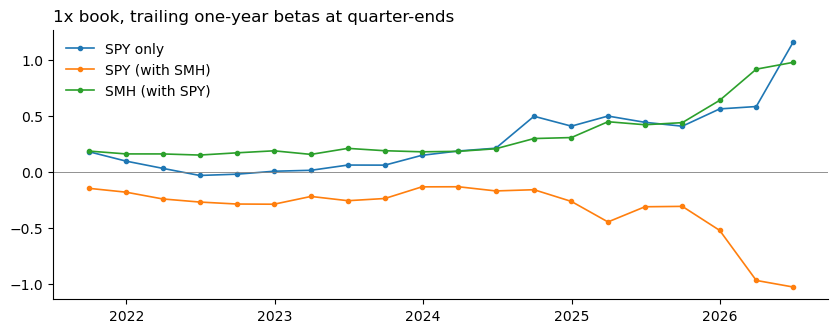

,2021-09-30,2021-12-31,2022-03-31,2022-06-30,2022-09-30,2022-12-30,2023-03-31,2023-06-30,2023-09-29,2023-12-29,2024-03-28,2024-06-28,2024-09-30,2024-12-31,2025-03-31,2025-06-30,2025-09-30,2025-12-31,2026-03-31,2026-06-30
SPY only,0.18,0.10,0.03,-0.03,-0.02,0.01,0.01,0.06,0.06,0.15,0.19,0.21,0.50,0.41,0.50,0.44,0.41,0.56,0.59,1.16
SPY (with SMH),-0.15,-0.18,-0.24,-0.27,-0.29,-0.29,-0.22,-0.26,-0.24,-0.13,-0.13,-0.17,-0.16,-0.26,-0.45,-0.31,-0.31,-0.52,-0.97,-1.03
SMH (with SPY),0.19,0.16,0.16,0.15,0.17,0.19,0.16,0.21,0.19,0.18,0.18,0.21,0.30,0.31,0.45,0.42,0.44,0.64,0.92,0.98


In [18]:
quarter_ends = excess.loc['2021-09':'2026-06'].index.to_series().groupby(excess.loc['2021-09':'2026-06'].index.to_period('Q')).max()
rolling_betas = {}
for date in quarter_ends:
    window = excess.loc[:date].iloc[-252:]
    y = window[NAMES] @ weights_1x
    rolling_betas[date.date()] = {
        'SPY only': regress(y, window[['SPY']]).params['SPY'],
        'SPY (with SMH)': regress(y, window[['SPY', 'SMH']]).params['SPY'],
        'SMH (with SPY)': regress(y, window[['SPY', 'SMH']]).params['SMH'],
    }
rolling_betas = pd.DataFrame(rolling_betas).T

fig, ax = plt.subplots(figsize=(10, 3.5))
rolling_betas.plot(ax=ax, marker='o', ms=3, lw=1.2)
ax.axhline(0, color='grey', lw=0.6)
ax.set_title('1x book, trailing one-year betas at quarter-ends', loc='left')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
plt.show()
rolling_betas.round(2).T

- No. With SPY alone, beta rose from near 0 to 0.2 through 2024 to 1.16 by June 2026. With SPY and SMH, SMH beta rose from about 0.2 to 0.98 and SPY beta fell to −1.03.
- The weights stayed fixed but the names changed (4.1). The long sleeve's SMH beta rose from 0.32 to 0.74 while its SPY beta given SMH fell from 0.30 to −0.14, so it became a semis position. The short sleeve's SMH loading went from −0.10 to +0.15, so software stopped offsetting the semis exposure and began adding to it.

## 4.3

For each factor set in 4.1 and each window, report the average pairwise correlation of the residuals among the long names, among the short names, and across the sleeves, next to the same averages for the raw returns. Then, for the 2025-01-02 to 2026-06-30 window, compute the 1x book's variance three ways: from the sample covariance of the twelve names; from the factor model with a diagonal residual covariance; from the factor model with the full residual covariance. Do this for `SPY` alone and for `SPY` plus `SMH`.

* Convert each variance to a 4x one-day Normal 5% VaR.

After the factors are removed, how many dimensions of risk are left in this book? Which term does the diagonal drop, and how large is it as a share of the book's variance?

#### Variance Decomposition

$\sigma^2_{\text{book}} = (B\boldsymbol{w})'\,\Sigma_f\,(B\boldsymbol{w}) + \boldsymbol{w}'\,\Sigma_\epsilon\,\boldsymbol{w}$. A factor risk model usually replaces $\Sigma_\epsilon$ with its diagonal; the sample covariance of the twelve names needs no such assumption.


In [19]:
def residuals(start, end, cols):
    f = excess.loc[start:end, cols]
    return pd.DataFrame({n: regress(excess.loc[start:end, n], f).resid for n in NAMES})

def corr_summary(corr):
    return {'long vs long': avg_corr(corr, LONGS, LONGS), 'short vs short': avg_corr(corr, SHORTS, SHORTS),
            'long vs short': avg_corr(corr, LONGS, SHORTS)}

table_4_3 = {}
for win, (start, end) in WINDOWS_4.items():
    table_4_3[(win, 'raw')] = corr_summary(excess.loc[start:end, NAMES].corr())
    for fs, cols in FACTOR_SETS.items():
        table_4_3[(win, f'resid {fs}')] = corr_summary(residuals(start, end, cols).corr())
pd.DataFrame(table_4_3).round(2)

2021-2024                         2025-2026H1            \
                     raw resid SPY resid SPY+SMH         raw resid SPY   
long vs long        0.42      0.19          0.11        0.55      0.39   
short vs short      0.51      0.25          0.25        0.50      0.41   
long vs short       0.34      0.03         -0.01        0.11     -0.12   

                              
               resid SPY+SMH  
long vs long            0.22  
short vs short          0.42  
long vs short          -0.04

In [20]:
start, end = WINDOWS_4['2025-2026H1']
z95 = -stats.norm.ppf(0.05)
sample_var = weights_1x @ excess.loc[start:end, NAMES].cov() @ weights_1x

rows = {'sample covariance': {'variance (daily)': sample_var}}
for fs, cols in FACTOR_SETS.items():
    f = excess.loc[start:end, cols]
    B = pd.DataFrame({n: regress(excess.loc[start:end, n], f).params[cols] for n in NAMES})
    resid_cov = residuals(start, end, cols).cov()
    exposure = B @ weights_1x
    factor_var = exposure @ f.cov() @ exposure
    diag_var = (weights_1x**2 * np.diag(resid_cov)).sum()
    full_var = weights_1x @ resid_cov @ weights_1x
    rows[f'{fs}, diagonal residual'] = {'variance (daily)': factor_var + diag_var}
    rows[f'{fs}, full residual'] = {'variance (daily)': factor_var + full_var,
                                    'off-diagonal share': (full_var - diag_var) / (factor_var + full_var)}
    eig = np.linalg.eigvalsh(residuals(start, end, cols).corr())[::-1]
    print(f'{fs}: share of residual correlation explained by first two eigenvectors: {eig[0]/eig.sum():.0%}, {eig[1]/eig.sum():.0%}')

table_4_3b = pd.DataFrame(rows).T
table_4_3b['4x Normal 5% VaR'] = 4 * z95 * np.sqrt(table_4_3b['variance (daily)'])
table_4_3b.style.format({'variance (daily)': '{:.6f}', 'off-diagonal share': '{:.0%}', '4x Normal 5% VaR': '{:.2%}'}, na_rep='')

SPY: share of residual correlation explained by first two eigenvectors: 34%, 19%
SPY+SMH: share of residual correlation explained by first two eigenvectors: 28%, 18%


,variance (daily),off-diagonal share,4x Normal 5% VaR
sample covariance,0.000463,,14.16%
"SPY, diagonal residual",0.000182,,8.86%
"SPY, full residual",0.000463,61%,14.16%
"SPY+SMH, diagonal residual",0.000311,,11.61%
"SPY+SMH, full residual",0.000463,33%,14.16%


SPY explains the cross-sleeve correlation (0.34 → about 0). Within each sleeve, correlation remains: in 2025-26 the residual correlation is 0.22 among the longs (after SMH) and 0.42 among the shorts. The first two eigenvectors of the residual correlation explain 28% and 18%.

| 1x variance, 2025-26 | 4x Normal 5% VaR |
|---|---|
| sample covariance | 14.2% |
| SPY, diagonal residual | 8.9% |
| SPY, full residual | 14.2% |
| SPY+SMH, diagonal residual | 11.6% |
| SPY+SMH, full residual | 14.2% |

The full-residual model reproduces the sample covariance exactly, because in-sample OLS residuals are uncorrelated with the factors. After the factors, **about two dimensions remain**: a long-theme factor (AI hardware) and a software factor, which this book holds as one long-short spread. The diagonal model drops the **within-sleeve residual covariances**. They are **61%** of the book's variance with SPY alone and **33%** with SPY+SMH, and dropping them cuts the VaR by 37% and 18%.

## 4.4

Attribute the July 24 to 29 loss of the 4x book to its factor exposure and its residual, as sums of daily contributions, using betas from each window and both factor sets from 4.1.

* Report the systematic share under each of the four combinations.

Was the reversal a factor event or a residual event, and does the answer depend on what you call a factor?


In [21]:
book_4x_excess = excess.loc[REVERSAL_DAYS, NAMES] @ weights
rows = {}
for win, (start, end) in WINDOWS_4.items():
    for fs, cols in FACTOR_SETS.items():
        exposure_4x = regress(portfolios['1x book'].loc[start:end], excess.loc[start:end, cols]).params[cols] * 4
        systematic = (excess.loc[REVERSAL_DAYS, cols] @ exposure_4x).sum()
        total = book_4x_excess.sum()
        rows[(win, fs)] = {'total (sum of daily)': total, 'systematic': systematic,
                           'residual': total - systematic, 'systematic share': systematic / total}
pd.DataFrame(rows).T.style.format('{:.1%}')

- Total is the sum of the four daily returns (−96.4%), not the compounded loss (−66.9%), because only a sum splits cleanly into factor and residual parts. Systematic is the sum of daily β′f with 4x betas; residual is the rest.
- The systematic share is 0.5% and 11.5% with 2021-24 betas (SPY, SPY+SMH), and 3.5% and 46% with 2025-26 betas.
- With SPY alone the reversal is a residual event, since SPY barely moved. Counting SMH as a factor with current betas, almost half is systematic: SMH fell 2% to 5% each day against about 3.5x SMH exposure.
- So the answer depends on what you call a factor and which betas you use. The remaining residual is the long-short theme spread (4.3), a factor the model leaves out.

# 5. Horizon and Survival


## 5.1

Compute daily log excess returns of the 1x and 4x books. For 2021-01-04 to 2024-12-31, 2025-01-02 to 2026-06-30 and 2021-01-04 to 2026-06-30, report

* the annualized arithmetic mean, the annualized log mean, the annualized volatility, and the gap between the two means
* for leverage 1x, 2x, 3x and 4x, the probability of underperforming cash over one month, one year and five years with the Barnstable formula, $\Pr\big[\texttt{r}_{t,t+h} < \texttt{r}^f_{t,t+h}\big] = \Phi\!\left(-\sqrt{h}\,\mu/\sigma\right)$, with $\mu$ and $\sigma$ the daily mean and standard deviation of the log excess return over cash
* a plot of the probability against horizon for the four leverage levels on the 2021 to 2024 parameters

What sign does the 4x log mean take in each window, and what produces the gap? At each leverage, does a longer horizon raise or lower the probability? State in one sentence how this relates to the argument Barnstable's trustees made about stocks.

#### Log Returns

Write $\texttt{r}_t = \ln(1+r_t)$ for the log return.


In [22]:
WINDOWS_5 = {'2021-2024': ('2021-01-04', '2024-12-31'), '2025-2026H1': ('2025-01-02', '2026-06-30'),
             '2021-2026H1': ('2021-01-04', '2026-06-30')}
HORIZONS = {'1 month': 21, '1 year': 252, '5 years': 1260}
LEVERAGE = [1, 2, 3, 4]

def log_params(r):
    log_r = np.log1p(r)
    return log_r.mean(), log_r.std()

rows_mean, rows_prob = {}, {}
for win, (start, end) in WINDOWS_5.items():
    for lev in [1, 4]:
        r = book_1x.loc[start:end] * lev
        mu, sd = log_params(r)
        rows_mean[(win, f'{lev}x')] = {'arith mean': r.mean() * 252, 'log mean': mu * 252,
                                       'vol': r.std() * np.sqrt(252), 'gap': r.mean() * 252 - mu * 252}
    for lev in LEVERAGE:
        mu, sd = log_params(book_1x.loc[start:end] * lev)
        rows_prob[(win, f'{lev}x')] = {h: stats.norm.cdf(-np.sqrt(days) * mu / sd) for h, days in HORIZONS.items()}

display(pd.DataFrame(rows_mean).T.style.format('{:+.1%}'))
pd.DataFrame(rows_prob).T.style.format('{:.1%}')

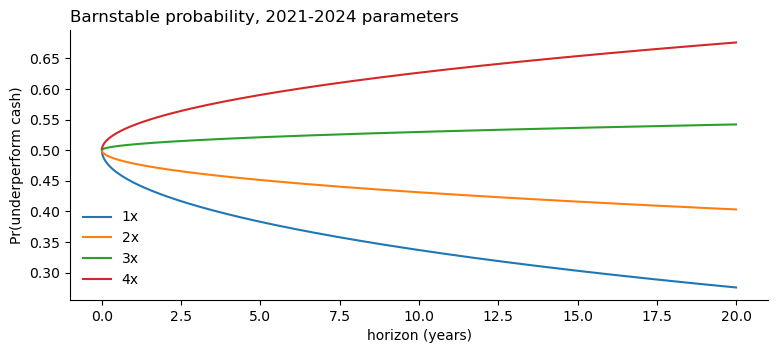

In [23]:
horizon_days = np.arange(1, 20 * 252 + 1)
fig, ax = plt.subplots(figsize=(9, 3.5))
for lev in LEVERAGE:
    mu, sd = log_params(book_1x.loc['2021-01-04':'2024-12-31'] * lev)
    ax.plot(horizon_days / 252, stats.norm.cdf(-np.sqrt(horizon_days) * mu / sd), label=f'{lev}x')
ax.set_xlabel('horizon (years)'); ax.set_ylabel('Pr(underperform cash)')
ax.set_title('Barnstable probability, 2021-2024 parameters', loc='left')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
plt.show()

**Answer 5.1.**

The 4x levered log returns are positive in each window aside from 2021-2024, where the strategy had a log mean return of -6.41% despite a positive arithmetic mean of 13.35%. From 2025-2026, though, the strategy had a log mean return of 327.75%, which then pulls the full window (2021-2026) log mean return to 84.04% despite the rough start from 2021-2024. The gap between the two means is volatility drag, approximately σ²/2, which scales with the square of leverage (1.24% at 1x vs 19.76% at 4x in 2021-2024) while the mean only scales linearly.

In 2021-2024, for the 1x and 2x levered portfolios, the longer horizon lowers the probability of underperforming cash. However, for the 3x and 4x portfolios the probability of underperforming cash increases with horizon (59.0% at 4x over five years); in the other windows it falls at every leverage. Barnstable's time-diversification argument (mean grows with h, volatility with √h) holds only when the log mean is positive, but at high leverage the volatility drag makes it negative (such as in the 2021-2024 period), so time makes underperformance more likely.

## 5.2

Simulate the probability that the 4x book suffers a maximum drawdown of at least 50% within one year and within five years, using the 2021-01-04 to 2026-06-30 parameters: once from a normal with the book's daily log mean and standard deviation, once by resampling the book's own daily returns. State the number of paths and random seed.

Compare the probabilities. Does the shape of the return distribution or the level of its volatility drive the answer? Explain how a drawdown from a running peak differs from a loss relative to initial wealth.

For each simulated path, cumulate log returns from initial wealth of one, track the running maximum including that initial value, and record the largest drawdown.


In [24]:
N_PATHS, SEED = 10_000, 42
log_4x = np.log1p(book_4x.loc['2021-01-04':'2026-06-30'])

def prob_big_drawdown(log_draws, threshold=0.5):
    wealth = np.cumsum(log_draws, axis=1)
    peak = np.maximum.accumulate(np.maximum(wealth, 0), axis=1)
    max_dd = 1 - np.exp((wealth - peak).min(axis=1))
    return (max_dd >= threshold).mean()

rng = np.random.default_rng(SEED)
table_5_2 = {}
for h, days in {'1 year': 252, '5 years': 1260}.items():
    normal_draws = rng.normal(log_4x.mean(), log_4x.std(), size=(N_PATHS, days))
    boot_draws = rng.choice(log_4x.values, size=(N_PATHS, days))
    table_5_2[h] = {'normal': prob_big_drawdown(normal_draws), 'bootstrap': prob_big_drawdown(boot_draws)}
print(f'{N_PATHS:,} paths per case, seed {SEED}')
pd.DataFrame(table_5_2).style.format('{:.1%}')

10,000 paths per case, seed 42


,1 year,5 years
normal,51.9%,98.6%
bootstrap,50.0%,98.0%


In [41]:
# Drawdown from running peak vs loss relative to initial wealth, same simulated paths
def prob_below_initial(log_draws, threshold=0.5):
    wealth = np.cumsum(log_draws, axis=1)                 # log wealth, starting from 0
    return (np.exp(wealth.min(axis=1)) <= threshold).mean()

rng = np.random.default_rng(SEED)                         # same seed, same draw order as above
table_initial = {}
for h, days in {'1 year': 252, '5 years': 1260}.items():
    normal_draws = rng.normal(log_4x.mean(), log_4x.std(), size=(N_PATHS, days))
    boot_draws = rng.choice(log_4x.values, size=(N_PATHS, days))
    table_initial[h] = {'normal': prob_below_initial(normal_draws), 'bootstrap': prob_below_initial(boot_draws)}

print('Pr[wealth ever falls to half of initial]')
pd.DataFrame(table_initial).style.format('{:.1%}')

Pr[wealth ever falls to half of initial]


,1 year,5 years
normal,16.9%,22.4%
bootstrap,16.6%,21.8%


**Answer 5.2.**

As demonstrated with the above Monte Carlo simulation (10,000 paths, seed 42) using normal and bootstrapped returns, the probability of a maximum drawdown of more than 50% in 1 year and 5 years is around 50% and 98%, respectively. This means that it is almost certain that the book will experience a fall of at least 50% in a 5 year horizon. The normal and bootstrapped probabilities are nearly identical (51.9% vs 50.0% at 1 year, 98.6% vs 98.0% at 5 years), so it is the level of volatility, not the shape of the distribution, that drives the answer. 

This does not mean, though, that the probability of losing 50% of initial wealth over 5 years is 98%. Rather, the max drawdown is measured from the running peak, which drifts up with wealth, so the positive mean offers no protection against it, while the probability that wealth ever falls below 50% of the initial value is only 22.4%.

## 5.3

As of June 30, 2026, what gross exposure would you have recommended for this mandate, on what criterion, and estimated on which window? Give the number and the reasoning.


In [25]:
rng = np.random.default_rng(SEED)
gross_grid = [0.5, 1, 1.5, 2, 2.5, 3, 4]
rows = {}
for gross in gross_grid:
    log_r = np.log1p(book_1x.loc['2021-01-04':'2026-06-30'] * gross)
    draws = rng.choice(log_r.values, size=(N_PATHS, 252))
    rows[f'{gross}x'] = {'ann vol': log_r.std() * np.sqrt(252), 'ann log mean': log_r.mean() * 252,
                         'P(max DD >= 30%, 1y)': prob_big_drawdown(draws, 0.3),
                         'P(max DD >= 50%, 1y)': prob_big_drawdown(draws, 0.5)}
pd.DataFrame(rows).T.style.format('{:.1%}')

,ann vol,ann log mean,"P(max DD >= 30%, 1y)","P(max DD >= 50%, 1y)"
0.5x,11.2%,15.0%,0.0%,0.0%
1x,22.4%,28.6%,2.8%,0.0%
1.5x,33.7%,41.1%,17.8%,0.5%
2x,44.9%,52.2%,41.1%,4.1%
2.5x,56.2%,62.1%,64.4%,11.9%
3x,67.5%,70.7%,80.8%,22.9%
4x,90.3%,84.0%,96.0%,50.8%


**I recommend 2x gross**, on the criterion that the probability of a 50% drawdown within one year should be at most 5% (bootstrap of the 2021-01-04 to 2026-06-30 daily returns). 

That probability is 4.1% at 2x, 11.9% at 2.5x and 50.8% at 4x. I use the full window because the drawdown probability depends mainly on volatility, which 5.5 years estimate well. The 18-month mean (standard error 112%) would make any leverage look safe. 2x means about 45% annual volatility, with a log mean of 52% that is still positive.

# 6. The Risk-Managed Mandate

The managed book keeps the twelve names, stays long the long sleeve and short the short sleeve, and never exceeds 4x gross. Every control uses only information available at the close before it acts. Every control is a rebalancing rule, and the constant-leverage comparators in 6.2 are daily-reset books at lower gross, so the comparison isolates timing from level.


## 6.1

Before computing any Section 6 result, and before using any return after July 31, 2026, write a dated markdown cell that states

* two numeric pass-fail criteria, one about risk and one about return or the cost of control
* the control or controls you will test, chosen from a volatility target, a VaR or CVaR limit, a drawdown rule, a factor hedge, a sleeve or position cap, or a combination
* every parameter

One well-motivated control is sufficient. You may use the risk measure or hedge developed in Section 7 as part of it; those questions still require their own analysis. Keep the original declaration. Record any revision in a second dated cell.


**Declaration, October 28, 2026.** Written before any Section 6 result and before using any return after July 31, 2026.

**Control: volatility target.** Gross for day $t$ is $g_t = \min\big(4,\; 4 \times 0.40 / \hat\sigma^{\text{ann}}_{t}\big)$, where $\hat\sigma^{\text{ann}}_t = \sqrt{252}\,\sigma_t$ is the EWMA forecast of the 4x book made at the close of $t-1$ (λ = 0.94, zero mean, seeded with the mean squared return of the first 21 days, as in 3.1). All twelve weights are scaled by $g_t/4$, so the sleeves stay equal-weighted, long the long sleeve and short the short sleeve. Rebalanced at every close.

Parameters: target 40% annualized, cap 4x gross, λ = 0.94, no floor. The 40% comes from 5.3: about 2x gross on the 2021-2026H1 volatility.

**Criteria** (apply to the report window and, in 6.3, to the holdout):

1. Risk: realized annualized volatility of the managed book ≤ 50% (1.25 × target).
2. Cost: managed Sharpe ratio no more than 0.5 below the constant-leverage comparator's Sharpe.

## 6.2

Implement the declared controls on the design window. Over the report window, 2025-01-02 to 2026-07-31, for the managed book, the unmanaged 4x book, the 1x book, and a constant-leverage comparator whose gross exposure equals the managed book's average gross over the report window, report

* gross exposure through time and the dates on which the controls bound
* cumulative return to July 23, the July 24 to 29 return, and cumulative return to July 31
* annualized volatility, Sharpe ratio and maximum drawdown
* average gross exposure, and the gross exposure set at the July 23 close (for July 24)

Compare each control with constant exposure at the same average gross leverage to distinguish timing from position size. State what each control cost or earned before the reversal and during it, against the unmanaged book and against its comparator, and whether an investor reviewing the managed book in April 2026 would have kept it.


average managed gross 1.49x, range 0.55x to 3.11x; volatility target binds on 395 of 395 days, the 4x cap on 0


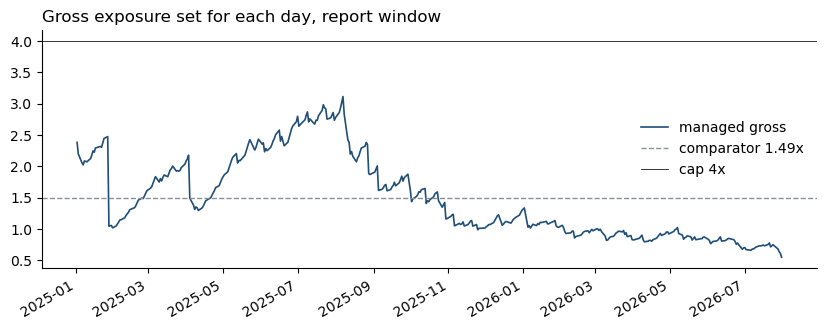

,cum to Jul 23,Jul 24-29,cum to Jul 31,ann vol,Sharpe,max drawdown,avg gross,gross for Jul 24
managed,+540.1%,-15.6%,+468.5%,+45.5%,2.67,-30.1%,1.49,0.75
unmanaged 4x,+8526.7%,-66.9%,+3712.8%,+148.3%,2.33,-82.3%,4.00,4.00
1x book,+310.4%,-22.0%,+247.5%,+37.1%,2.33,-30.2%,1.00,1.00
constant 1.49x,+661.0%,-31.3%,+488.9%,+55.2%,2.33,-42.3%,1.49,1.49


In [26]:
TARGET_VOL, MAX_GROSS = 0.40, 4.0
RISK_LIMIT, SHARPE_TOLERANCE = 1.25 * TARGET_VOL, 0.5

def managed_gross(sigma_daily):
    """Gross for day t from the EWMA forecast made at the t-1 close."""
    return np.minimum(MAX_GROSS, MAX_GROSS * TARGET_VOL / (sigma_daily * np.sqrt(252)))

def perf(r):
    nav_ = (1 + r).cumprod()
    return {'ann vol': r.std() * np.sqrt(252), 'Sharpe': r.mean() / r.std() * np.sqrt(252),
            'max drawdown': (nav_ / np.maximum(nav_.cummax(), 1) - 1).min()}

gross_design = managed_gross(forecasts['sigma']).loc[REPORT_START:]
avg_gross = gross_design.mean()
r4 = book_4x.loc[REPORT_START:]
books_6_2 = {
    'managed': gross_design / 4 * r4,
    'unmanaged 4x': r4,
    '1x book': r4 / 4,
    f'constant {avg_gross:.2f}x': avg_gross / 4 * r4,
}
gross_paths = {'managed': gross_design, 'unmanaged 4x': 4, '1x book': 1, f'constant {avg_gross:.2f}x': avg_gross}

def report(books, gross_paths, reversal=True):
    table = {}
    for name, r in books.items():
        g = gross_paths[name] * pd.Series(1.0, index=r.index)
        row = {'cum return': (1 + r).prod() - 1}
        if reversal:
            row = {'cum to Jul 23': (1 + r.loc[:'2026-07-23']).prod() - 1,
                   'Jul 24-29': (1 + r.loc['2026-07-24':'2026-07-29']).prod() - 1,
                   'cum to Jul 31': (1 + r).prod() - 1}
        row.update(perf(r))
        row['avg gross'] = g.mean()
        if reversal:
            row['gross for Jul 24'] = g.loc['2026-07-24']
        table[name] = row
    return pd.DataFrame(table).T

at_cap = gross_design >= MAX_GROSS
print(f'average managed gross {avg_gross:.2f}x, range {gross_design.min():.2f}x to {gross_design.max():.2f}x; '
      f'volatility target binds on {(~at_cap).sum()} of {len(gross_design)} days, the 4x cap on {at_cap.sum()}')

fig, ax = plt.subplots(figsize=(10, 3.5))
gross_design.plot(ax=ax, color='#1f4e79', lw=1.2, label='managed gross')
ax.axhline(avg_gross, color='#8a8f98', ls='--', lw=1, label=f'comparator {avg_gross:.2f}x')
ax.axhline(MAX_GROSS, color='#14181e', lw=0.6, label='cap 4x')
ax.set_title('Gross exposure set for each day, report window', loc='left'); ax.set_xlabel('')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
plt.show()

report(books_6_2, gross_paths).style.format('{:+.1%}').format('{:.2f}', subset=['Sharpe', 'avg gross', 'gross for Jul 24'])

In [27]:
april = {name: perf(r.loc[:'2026-04-30']) | {'cum return': (1 + r.loc[:'2026-04-30']).prod() - 1}
         for name, r in books_6_2.items()}
print('review at April 30, 2026')
pd.DataFrame(april).T.style.format('{:+.1%}').format('{:.2f}', subset=['Sharpe'])

review at April 30, 2026


,ann vol,Sharpe,max drawdown,cum return
managed,+45.3%,3.22,-30.1%,+489.8%
unmanaged 4x,+124.2%,3.42,-47.8%,+9295.0%
1x book,+31.0%,3.42,-12.1%,+279.7%
constant 1.49x,+46.2%,3.42,-18.1%,+593.9%


At 0.75x on July 23, the control had already cut gross before the reversal, because EWMA volatility was at a record. The volatility target bound on every day of the report window (gross 0.55x to 3.11x, average 1.49x), so the 4x cap never mattered.

**Timing vs size.** Against the constant 1.49x book:
- Before the reversal, timing **cost** about 120 points (+540% vs +661% to July 23). Volatility and returns rose together in 2025-26, so the control was small when returns were largest.
- During the reversal it **earned** about 16 points: −15.6% vs −31.3%.
- By July 31 it trails by 20 points but has a higher Sharpe (2.67 vs 2.33) and a smaller drawdown (−30% vs −42%).

Almost all of the gap to the unmanaged book (+469% vs +3,713%) comes from **size, not timing**. The two criteria pass on the report window: volatility 45.5% and Sharpe gap +0.34.

**April 2026 review.** The managed book was behind its comparator on return (+490% vs +594%), Sharpe (3.22 vs 3.42) and drawdown (−30% vs −18%, from a January 2025 hit while it was at about 3x). An investor at that point would probably have dropped it: the cost showed up before the payoff did.

## 6.3

Run the same controls, unchanged, from August 3, 2026 to the end of the file, with the same comparators.

* Report the same statistics plus the worst day.
* Apply the criteria declared in 6.1: pass or fail, by your own test.

If the design window and the holdout disagree about a control, say which you believe and why.


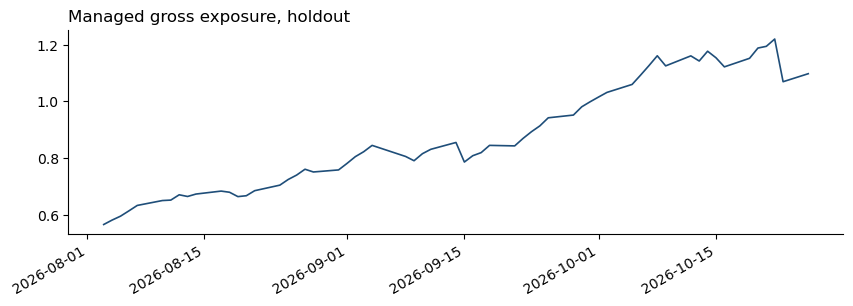

,cum return,ann vol,Sharpe,max drawdown,avg gross,worst day
managed,-12.5%,+32.7%,-1.56,-21.0%,0.87,-6.2%
unmanaged 4x,-45.0%,+150.5%,-0.89,-60.2%,4.00,-23.7%
1x book,-9.2%,+37.6%,-0.89,-18.1%,1.00,-5.9%
constant 1.49x,-14.5%,+56.0%,-0.89,-26.0%,1.49,-8.8%


,report window,holdout
risk: managed vol <= 50%,45.5% -> PASS,32.7% -> PASS
cost: Sharpe gap to comparator >= -0.5,+0.34 -> PASS,-0.66 -> FAIL


In [28]:
# holdout opened here for the first time
book_4x_full = returns[NAMES] @ weights
sigma_full = ewma_sigma(book_4x_full)
r_hold = book_4x_full.loc[HOLDOUT_START:]
gross_hold = managed_gross(sigma_full).loc[HOLDOUT_START:]
books_6_3 = {
    'managed': gross_hold / 4 * r_hold,
    'unmanaged 4x': r_hold,
    '1x book': r_hold / 4,
    f'constant {avg_gross:.2f}x': avg_gross / 4 * r_hold,
}
table_6_3 = report(books_6_3, gross_paths | {'managed': gross_hold}, reversal=False)
table_6_3['worst day'] = [r.min() for r in books_6_3.values()]

comparator = f'constant {avg_gross:.2f}x'
verdict = {}
for label, tab in {'report window': report(books_6_2, gross_paths), 'holdout': table_6_3}.items():
    verdict[label] = {
        f'risk: managed vol <= {RISK_LIMIT:.0%}': f"{tab.loc['managed', 'ann vol']:.1%} -> " +
            ('PASS' if tab.loc['managed', 'ann vol'] <= RISK_LIMIT else 'FAIL'),
        f'cost: Sharpe gap to comparator >= -{SHARPE_TOLERANCE}': f"{tab.loc['managed', 'Sharpe'] - tab.loc[comparator, 'Sharpe']:+.2f} -> " +
            ('PASS' if tab.loc['managed', 'Sharpe'] - tab.loc[comparator, 'Sharpe'] >= -SHARPE_TOLERANCE else 'FAIL'),
    }

fig, ax = plt.subplots(figsize=(10, 3))
gross_hold.plot(ax=ax, color='#1f4e79', lw=1.2)
ax.set_title('Managed gross exposure, holdout', loc='left'); ax.set_xlabel('')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

display(table_6_3.style.format('{:+.1%}').format('{:.2f}', subset=['Sharpe', 'avg gross']))
pd.DataFrame(verdict)

- Holdout: the managed book lost 12.5% at 32.7% volatility (worst day −6.2%, average gross 0.87x), against −45.0% for the unmanaged 4x book (worst day −23.7%) and −14.5% for the 1.49x comparator (worst day −8.8%).
- Verdict: the risk criterion passes (32.7% ≤ 50%); the cost criterion fails (Sharpe gap −0.66 vs a −0.5 tolerance).
- The cost failure is real. A constant book's Sharpe does not depend on its leverage, so the Sharpe gap compares returns at equal risk: a constant 0.87x book, with the managed book's holdout average gross and the same volatility, lost only 7.9% against 12.5%. The managed book lost less than the 1.49x comparator only because it held less gross.
- The two windows disagree on timing: at equal volatility it added about 122 points in the report window (+469% vs +347% for a constant 1.23x book), almost all from the July reversal, and cost 4.6 points in the holdout. I believe the risk result, which held in both windows; one crash and one quarter are not evidence that the timing gain repeats.

***


# 7. Reporting and Recommendation

Choose the additional risk measure, hedge specification, dashboard item, and final recommendation. Support each choice with the relevant comparison; the required analysis can justify different decisions.


## 7.1

Propose one risk number a risk manager should have reported beside the one-day 5% VaR for this book, built from the same inputs. Define it, compute it daily through the design window, and report the forecast made at the June 22, July 1 and July 23, 2026 closes (for the following day). Justify the choice in course terms.


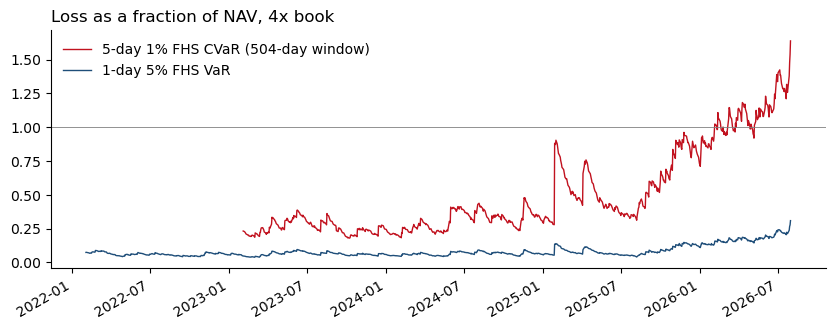

,2026-06-22,2026-07-01,2026-07-23
for day,2026-06-23,2026-07-02,2026-07-24
1-day 5% FHS VaR,19.4%,24.2%,21.3%
5-day 1% stress CVaR,117.4%,140.1%,125.7%


In [29]:
STRESS_ALPHA, STRESS_DAYS, STRESS_WINDOW = 0.01, 5, 504
z_design = (book_4x / forecasts['sigma']).values
stress_cvar = pd.Series(np.nan, index=book_4x.index)
for t in range(STRESS_WINDOW + INIT_DAYS, len(book_4x)):
    stress_cvar.iloc[t] = tail_stats(z_design[t - STRESS_WINDOW:t], STRESS_ALPHA)[1] * forecasts['sigma'].iloc[t] * np.sqrt(STRESS_DAYS)

fig, ax = plt.subplots(figsize=(10, 3.5))
stress_cvar.plot(ax=ax, color='#c1121f', lw=1, label='5-day 1% FHS CVaR (504-day window)')
forecasts['FHS VaR'].plot(ax=ax, color='#1f4e79', lw=1, label='1-day 5% FHS VaR')
ax.axhline(1, color='grey', lw=0.6)
ax.set_title('Loss as a fraction of NAV, 4x book', loc='left'); ax.set_xlabel('')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
plt.show()

next_day = lambda d: book_4x.index[book_4x.index.get_loc(pd.Timestamp(d)) + 1]
pd.DataFrame({d: {'for day': next_day(d).date(), '1-day 5% FHS VaR': f"{forecasts.loc[next_day(d), 'FHS VaR']:.1%}",
                  '5-day 1% stress CVaR': f'{stress_cvar.loc[next_day(d)]:.1%}'}
              for d in ['2026-06-22', '2026-07-01', '2026-07-23']})

**Proposed number: 5-day 1% CVaR from FHS**, using a 504-day standardization window and scaled by √5 from one day. It uses the same returns and EWMA volatility as the VaR.

| Close | 1-day 5% VaR | 5-day 1% CVaR |
|---|---|---|
| Jun 22 | 19.4% | 117% |
| Jul 1 | 24.2% | 140% |
| Jul 23 | 21.3% | 126% |

Why this number:
1. VaR says nothing beyond its quantile. CVaR measures the size of the tail loss and is coherent.
2. 1% instead of 5% looks at the tail that ends a fund.
3. Five days is a realistic time to cut a $400mm+ crowded book, and 3.3 shows that losses cluster.
4. FHS keeps the book's own fat tails, rescaled to today's volatility. The 504-day window keeps January 2025, which 3.4 showed the 252-day window loses.

A number above 100% says a bad week wipes out NAV. A one-day VaR of 20% hides that.

## 7.2

Design a hedge overlay for the 4x book using trailing-window betas to one or more of `SPY`, `SMH` and the sector ETFs, refreshed at a frequency you choose.

* Report the overlay positions as multiples of NAV.
* Report the hedged book's annualized volatility, Sharpe ratio and July 24 to 29 return over the report window, against the unhedged book.

Recommend for or against running it. Include the position sizes in the recommendation.


In [30]:
HEDGE_WINDOW, HEDGE_FACTORS = 126, ['SPY', 'SMH']
ex_design = excess.loc[:DESIGN_END]
book_4x_ex = ex_design[NAMES] @ weights
month_end_closes = ex_design.index.to_series().groupby(ex_design.index.to_period('M')).max()

hedge_at_close = pd.DataFrame({
    d: -regress(book_4x_ex.loc[:d].iloc[-HEDGE_WINDOW:], ex_design.loc[:d, HEDGE_FACTORS].iloc[-HEDGE_WINDOW:]).params[HEDGE_FACTORS]
    for d in month_end_closes if d >= pd.Timestamp('2024-11-29')
}).T
hedge = hedge_at_close.reindex(ex_design.index).ffill().shift(1).loc[REPORT_START:]
hedged_4x = r4 + (hedge * ex_design.loc[REPORT_START:, HEDGE_FACTORS]).sum(axis=1)

print('overlay positions, x NAV, set at month-end closes')
display(hedge_at_close.loc['2024-12':].rename(index=lambda d: d.date()).round(2).T)

pd.DataFrame({name: perf(r) | {'Jul 24-29': (1 + r.loc['2026-07-24':'2026-07-29']).prod() - 1}
              for name, r in {'unhedged 4x': r4, 'hedged 4x': hedged_4x}.items()}).T.style.format('{:+.1%}').format('{:.2f}', subset=['Sharpe'])

overlay positions, x NAV, set at month-end closes


,2024-12-31,2025-01-31,2025-02-28,2025-03-31,2025-04-30,2025-05-30,2025-06-30,2025-07-31,2025-08-29,2025-09-30,2025-10-31,2025-11-28,2025-12-31,2026-01-30,2026-02-27,2026-03-31,2026-04-30,2026-05-29,2026-06-30,2026-07-31
SPY,0.89,2.16,2.10,1.93,1.58,2.00,2.15,0.75,0.93,0.70,0.97,0.68,-0.23,2.54,3.70,6.01,5.85,6.80,6.91,6.82
SMH,-1.29,-2.02,-1.98,-1.92,-1.94,-2.24,-2.34,-1.44,-1.56,-1.52,-2.13,-2.66,-2.56,-3.60,-3.85,-5.04,-5.06,-5.01,-4.67,-4.90


,ann vol,Sharpe,max drawdown,Jul 24-29
unhedged 4x,+148.3%,2.33,-82.3%,-66.9%
hedged 4x,+104.6%,1.98,-70.5%,-34.7%


**Overlay design.** Each month-end close, regress the 4x book's excess return on SPY and SMH over the trailing 126 days and hold −β (as multiples of NAV) for the next month. The position set June 30, 2026 is **+6.9x NAV in SPY and −4.7x NAV in SMH**. In early 2025 it was about +2x SPY and −2x SMH.

| Report window | Vol | Sharpe | Max DD | Jul 24-29 |
|---|---|---|---|---|
| unhedged 4x | 148% | 2.33 | −82% | −66.9% |
| hedged 4x | 105% | 1.98 | −71% | −34.7% |

**I recommend against running it.** It halves the reversal loss, but it adds about 11.6x NAV of ETF gross on top of the book's 4x. The betas are unstable (the SPY leg went from −0.2x to +6.9x in six months), and the Sharpe falls. The hedged book still runs at 105% volatility because most of the risk is the residual theme spread (4.3), which SPY and SMH do not cover. Cutting gross (Section 6) removes more risk with no added positions.

## 7.3

Build the one-page view a risk manager should have had at the July 23, 2026 close, from data through that date only: a small table or a few figures covering

* the volatility level and its history
* the VaR and CVaR forecast made at that close (for the following day)
* the drawdown from peak, the factor exposures, and one item of your choice

Produce the same page for the June 22, 2026 close. For each date, say in three or four sentences what the page showed and what action it supported.


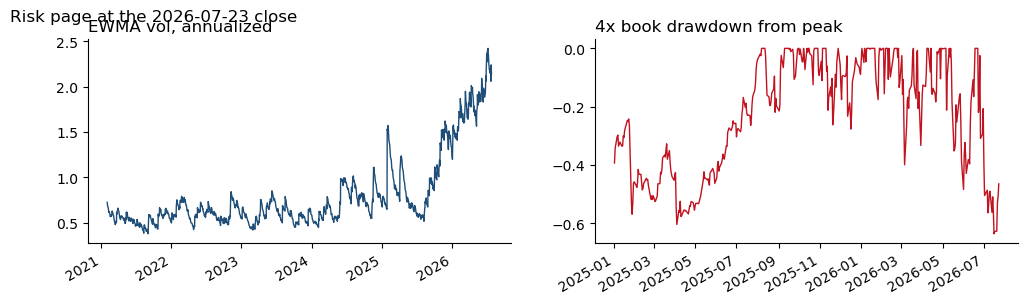

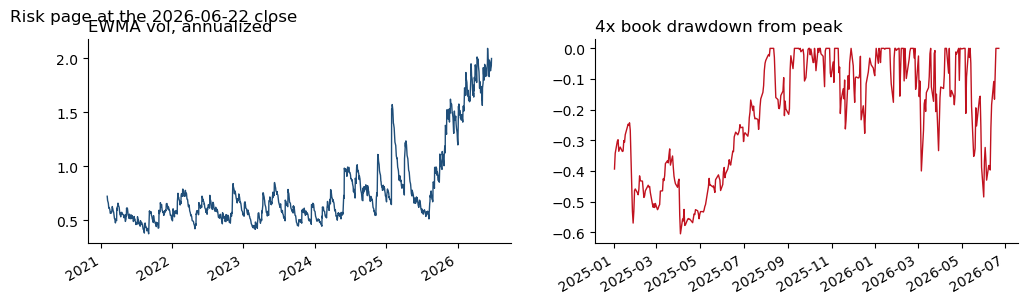

,2026-07-23 close,2026-06-22 close
"EWMA vol, ann (forecast for next day)",214%,200%
percentile of own history,99%,100%
HS VaR / CVaR,16.6% / 20.9%,15.0% / 18.4%
EWMA VaR / CVaR,22.2% / 27.8%,20.7% / 26.0%
FHS VaR / CVaR,21.3% / 27.3%,19.4% / 24.9%
drawdown from peak,-46.5%,0.0%
"beta SPY / SMH (1y, 4x)",-4.67 / 4.17,-3.82 / 3.72
5-day 1% stress CVaR,126%,117%


In [31]:
nav_4x = (1 + book_4x).cumprod()

def risk_page(close):
    close = pd.Timestamp(close)
    day = next_day(close)
    vol_hist = ewma_ann.loc[:day].dropna()
    window = ex_design.loc[:close].iloc[-252:]
    betas = regress(window[NAMES] @ weights, window[['SPY', 'SMH']]).params
    drawdown = nav_4x.loc[:close] / nav_4x.loc[:close].cummax() - 1
    page = pd.Series({
        'EWMA vol, ann (forecast for next day)': f'{vol_hist.iloc[-1]:.0%}',
        'percentile of own history': f'{(vol_hist.iloc[:-1] < vol_hist.iloc[-1]).mean():.0%}',
        'HS VaR / CVaR': f"{forecasts.loc[day, 'HS VaR']:.1%} / {forecasts.loc[day, 'HS CVaR']:.1%}",
        'EWMA VaR / CVaR': f"{forecasts.loc[day, 'EWMA VaR']:.1%} / {forecasts.loc[day, 'EWMA CVaR']:.1%}",
        'FHS VaR / CVaR': f"{forecasts.loc[day, 'FHS VaR']:.1%} / {forecasts.loc[day, 'FHS CVaR']:.1%}",
        'drawdown from peak': f'{drawdown.iloc[-1]:.1%}',
        'beta SPY / SMH (1y, 4x)': f"{betas['SPY']:.2f} / {betas['SMH']:.2f}",
        '5-day 1% stress CVaR': f'{stress_cvar.loc[day]:.0%}',
    }, name=f'{close.date()} close')

    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    vol_hist.plot(ax=axes[0], color='#1f4e79', lw=1)
    axes[0].set_title('EWMA vol, annualized', loc='left')
    drawdown.loc['2025':].plot(ax=axes[1], color='#c1121f', lw=1)
    axes[1].set_title('4x book drawdown from peak', loc='left')
    for ax in axes:
        ax.set_xlabel(''); ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle(f'Risk page at the {close.date()} close', x=0.06, ha='left')
    plt.show()
    return page

pd.concat([risk_page('2026-07-23'), risk_page('2026-06-22')], axis=1)

**June 22.** The book was at its peak (drawdown 0%), but EWMA volatility was 200%, the highest it had ever been. VaR was 15% to 21% a day, the book was about −3.8x SPY and +3.7x SMH, and the 5-day stress CVaR was 117% of NAV. The page supported **cutting gross now, at the peak** (the volatility target gives about 0.8x). The drawdown said nothing, while volatility and the stress number said everything.

**July 23.** The book was 46.5% below the June peak, with volatility at 214% (99th percentile), VaR 17% to 22%, CVaR 21% to 28%, the factor bet larger (−4.7x SPY, +4.2x SMH) and stress CVaR at 126%. The page supported **cutting to at most 1x immediately** (the control gives 0.75x) rather than waiting for VaR breaches. One more bad week could exhaust NAV, and four days later the 4x book had lost 67%.

## 7.4

In half a page, state the gross exposure and controls under which you would run this mandate going forward, drawing on the design results and the holdout verdict in 6.3, what the mandate's investors give up for them, and one observable result over the next year that would make you reverse the decision.


- Going forward I would run the volatility target as declared in 6.1 (40% annualized, EWMA λ = 0.94, rebalanced daily) with the gross cap lowered from 4x to 2x, the level 5.3 supports on the design data. The 5-day 1% stress CVaR from 7.1 goes on the daily report, with a risk-committee review above 50% of NAV. I would not run the beta overlay (7.2).
- The case for the control is risk, not return. It held volatility near target in both windows (45% and 33%) and halved the reversal loss against its same-gross comparator. Its timing did not repeat out-of-sample: in the holdout it lost 4.6 points more than a constant book at the same volatility, and it failed the cost criterion.
- The 2x cap would not have bound in the holdout (gross peaked at 1.22x), so it is a limit for calm periods, not a change fitted to the holdout.
- Investors give up most of the upside of a leveraged trend (+469% instead of +3,713% over the report window) and accept periods, such as April 2026 and the holdout, when the control trails a constant-leverage book of the same risk. In exchange the book should not lose 80% of NAV.
- I would reverse the decision if the managed book's realized volatility over any three-month window in the next year exceeds 50% (1.25 × target), which would mean the EWMA forecast is not tracking this book; I would then run a fixed 1x gross.